**Task 5: Analytics Report - NYC Yellow Taxi Business Analysis Stakeholder: taxi fleet operator Business objective: find when, where and on what kind of trips the fleet earns the most, so cars can be placed better. Data: NYC TLC Yellow Taxi Trip Records (latest available month) + Taxi Zone Lookup **

In [1]:
import pandas as pd

# try the newest months first, use the first one that downloads
base = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{}.parquet"
months = ["2026-09", "2026-08", "2026-07", "2026-06", "2026-05", "2026-04", "2026-03", "2026-02", "2026-01", "2025-12"]

df = None
for m in months:
    try:
        df = pd.read_parquet(base.format(m))
        print("loaded month:", m)
        break
    except Exception as e:
        print(m, "not available")

# zone names (pickup and drop-off IDs map to these)
zones = pd.read_csv("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv")

print("\ntrips shape:", df.shape)
print("zones shape:", zones.shape)
print("\ncolumns:", list(df.columns))
print("\nfirst 3 rows:")
print(df.head(3).to_string())
print("\ninfo:")
df.info()
print("\nzones head:")
print(zones.head(3).to_string())

2026-09 not available
loaded month: 2026-08

trips shape: (3336716, 21)
zones shape: (265, 4)

columns: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'request_source']

first 3 rows:
   VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  trip_distance  RatecodeID store_and_fwd_flag  PULocationID  DOLocationID  payment_type  fare_amount  extra  mta_tax  tip_amount  tolls_amount  improvement_surcharge  total_amount  congestion_surcharge  Airport_fee  cbd_congestion_fee request_source
0         1  2026-08-01 00:03:04   2026-08-01 00:07:51              1.0            0.6         1.0                  N           140           262             1          6.5    3.5      0.5    

**load data**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# try newest months first, use the first one that downloads
base = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{}.parquet"
months = ["2026-09", "2026-08", "2026-07", "2026-06", "2026-05", "2026-04", "2026-03", "2026-02", "2026-01", "2025-12"]

df = None
for m in months:
    try:
        df = pd.read_parquet(base.format(m))
        month_used = m
        print("loaded month:", m)
        break
    except Exception:
        print(m, "not available")

zones = pd.read_csv("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv")

print("raw shape:", df.shape)
print(list(df.columns))
df.head()

2026-09 not available
loaded month: 2026-08
raw shape: (3336716, 21)
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'request_source']


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,N,140,262,1,...,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,None
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,N,140,262,1,...,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,None
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.0,1.10,1.0,N,140,263,1,...,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,None
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,N,164,80,1,...,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,None
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,N,148,141,1,...,1.0,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,None


**cleaning**

In [3]:
rows_before = len(df)

# trip time and duration in minutes
df["pickup"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["dropoff"] = pd.to_datetime(df["tpep_dropoff_datetime"])
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60

# keep only trips that start inside the chosen month (the file has a few stray dates)
y, mth = int(month_used[:4]), int(month_used[5:])
df = df[(df["pickup"].dt.year == y) & (df["pickup"].dt.month == mth)]

# remove impossible trips
df = df[(df["trip_distance"] >= 0.1) & (df["trip_distance"] <= 100)]
df = df[(df["fare_amount"] > 0) & (df["fare_amount"] <= 500)]
df = df[(df["total_amount"] > 0) & (df["total_amount"] <= 600)]
df = df[(df["duration_min"] >= 1) & (df["duration_min"] <= 180)]

# remove duplicate rows
df = df.drop_duplicates()

# new columns we need for analysis
df["hour"] = df["pickup"].dt.hour
df["day_name"] = df["pickup"].dt.day_name()
df["is_weekend"] = df["pickup"].dt.dayofweek >= 5
df["speed_mph"] = df["trip_distance"] / (df["duration_min"] / 60)
df = df[df["speed_mph"] <= 80]   # a taxi cannot average more than 80 mph

# payment type names (TLC data dictionary)
pay_names = {0: "Flex fare", 1: "Credit card", 2: "Cash", 3: "No charge", 4: "Dispute", 5: "Unknown", 6: "Voided"}
df["payment"] = df["payment_type"].map(pay_names).fillna("Other")

# tip percentage (tips are only recorded for card payments)
df["tip_pct"] = np.where(df["payment_type"] == 1, df["tip_amount"] / df["fare_amount"] * 100, np.nan)

# join zone names for pickup and drop-off
pu = zones[["LocationID", "Borough", "Zone"]].rename(columns={"LocationID": "PULocationID", "Borough": "pu_borough", "Zone": "pu_zone"})
do = zones[["LocationID", "Zone"]].rename(columns={"LocationID": "DOLocationID", "Zone": "do_zone"})
df = df.merge(pu, on="PULocationID", how="left").merge(do, on="DOLocationID", how="left")

df["is_airport"] = df["pu_zone"].str.contains("Airport", na=False) | df["do_zone"].str.contains("Airport", na=False)

print("rows before cleaning:", rows_before)
print("rows after cleaning :", len(df))
print("removed:", rows_before - len(df), "(", round((rows_before - len(df)) / rows_before * 100, 2), "% )")
print("missing values in key columns:")
print(df[["passenger_count", "pu_zone", "do_zone", "total_amount"]].isnull().sum())

rows before cleaning: 3336716
rows after cleaning : 3134641
removed: 202075 ( 6.06 % )
missing values in key columns:
passenger_count    822664
pu_zone              2392
do_zone              2351
total_amount            0
dtype: int64


**KPIs**

In [4]:
total_trips = len(df)
total_revenue = df["total_amount"].sum()

kpi = {
    "Total trips": total_trips,
    "Total revenue ($)": round(total_revenue),
    "Average revenue per trip ($)": round(df["total_amount"].mean(), 2),
    "Average fare ($)": round(df["fare_amount"].mean(), 2),
    "Average distance (miles)": round(df["trip_distance"].mean(), 2),
    "Average duration (min)": round(df["duration_min"].mean(), 1),
    "Revenue per mile ($)": round(df["total_amount"].sum() / df["trip_distance"].sum(), 2),
    "Revenue per minute ($)": round(df["total_amount"].sum() / df["duration_min"].sum(), 2),
    "Average tip, card trips (%)": round(df["tip_pct"].mean(), 1),
    "Card payment share (%)": round((df["payment_type"] == 1).mean() * 100, 1),
    "Cash payment share (%)": round((df["payment_type"] == 2).mean() * 100, 1),
    "Airport trips share (%)": round(df["is_airport"].mean() * 100, 1),
    "Weekend trips share (%)": round(df["is_weekend"].mean() * 100, 1),
}
kpi_table = pd.DataFrame(list(kpi.items()), columns=["KPI", "Value"])
print("Month analysed:", month_used)
print(kpi_table.to_string(index=False))

Month analysed: 2026-08
                         KPI       Value
                 Total trips  3134641.00
           Total revenue ($) 94210631.00
Average revenue per trip ($)       30.05
            Average fare ($)       21.01
    Average distance (miles)        3.74
      Average duration (min)       17.30
        Revenue per mile ($)        8.03
      Revenue per minute ($)        1.74
 Average tip, card trips (%)       25.00
      Card payment share (%)       63.40
      Cash payment share (%)        9.80
     Airport trips share (%)        9.20
     Weekend trips share (%)       33.80


**Chart 1, trips and revenue per trip by hour**

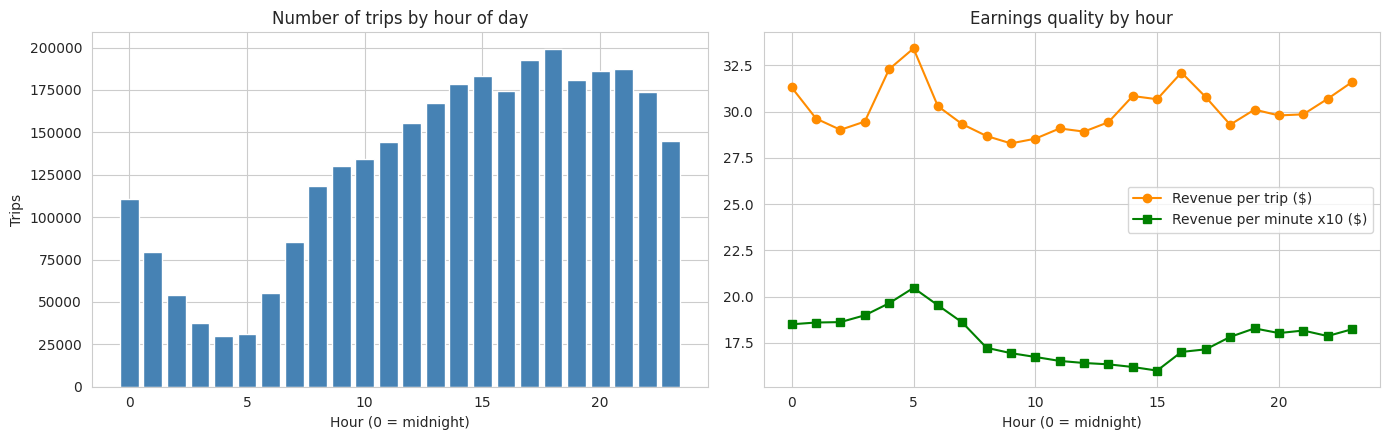

 hour  trips  rev_per_trip  rev_per_min
    0 110891         31.31         1.85
    1  79476         29.63         1.86
    2  53922         29.02         1.86
    3  37493         29.47         1.90
    4  29798         32.30         1.96
    5  30967         33.42         2.05
    6  55063         30.30         1.95
    7  85382         29.33         1.86
    8 118333         28.68         1.72
    9 130232         28.29         1.69
   10 134380         28.54         1.67
   11 144601         29.09         1.65
   12 155639         28.92         1.64
   13 167590         29.43         1.63
   14 178409         30.85         1.62
   15 183006         30.67         1.60
   16 174645         32.12         1.70
   17 192817         30.78         1.71
   18 199032         29.30         1.78
   19 180668         30.11         1.83
   20 186168         29.80         1.80
   21 187162         29.86         1.82
   22 173993         30.70         1.79
   23 144974         31.60         1.82


In [5]:
hourly = df.groupby("hour").agg(trips=("total_amount", "size"), rev_per_trip=("total_amount", "mean"),
                                 rev_per_min=("total_amount", lambda s: s.sum())).reset_index()
hourly["rev_per_min"] = hourly["rev_per_min"] / df.groupby("hour")["duration_min"].sum().values

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(hourly["hour"], hourly["trips"], color="steelblue")
ax[0].set_title("Number of trips by hour of day")
ax[0].set_xlabel("Hour (0 = midnight)"); ax[0].set_ylabel("Trips")

ax[1].plot(hourly["hour"], hourly["rev_per_trip"], marker="o", color="darkorange", label="Revenue per trip ($)")
ax[1].plot(hourly["hour"], hourly["rev_per_min"] * 10, marker="s", color="green", label="Revenue per minute x10 ($)")
ax[1].set_title("Earnings quality by hour")
ax[1].set_xlabel("Hour (0 = midnight)"); ax[1].legend()
plt.tight_layout(); plt.show()

print(hourly.round(2).to_string(index=False))

**Chart 2, day of week**

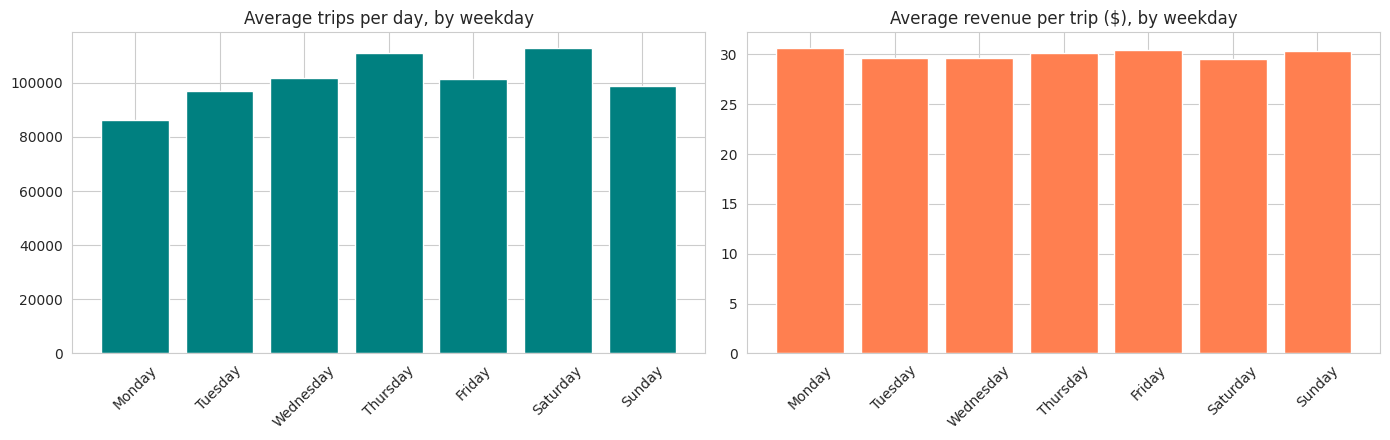

            trips      revenue  rev_per_trip  trips_per_day
day_name                                                   
Monday     431753  13243611.27         30.67        86351.0
Tuesday    387654  11503041.86         29.67        96914.0
Wednesday  407280  12056122.70         29.60       101820.0
Thursday   443388  13379974.41         30.18       110847.0
Friday     405059  12313277.22         30.40       101265.0
Saturday   564900  16696492.24         29.56       112980.0
Sunday     494607  15018111.09         30.36        98921.0


In [6]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = df.groupby("day_name").agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"),
                                  rev_per_trip=("total_amount", "mean")).reindex(order)
# some weekdays occur 5 times in a month, so also look at the average per day
n_days = df.groupby("day_name")["pickup"].apply(lambda s: s.dt.date.nunique()).reindex(order)
dow["trips_per_day"] = (dow["trips"] / n_days).round()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(dow.index, dow["trips_per_day"], color="teal")
ax[0].set_title("Average trips per day, by weekday"); ax[0].tick_params(axis="x", rotation=45)
ax[1].bar(dow.index, dow["rev_per_trip"], color="coral")
ax[1].set_title("Average revenue per trip ($), by weekday"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print(dow.round(2).to_string())

**Chart 3, heatmap (day x hour)**

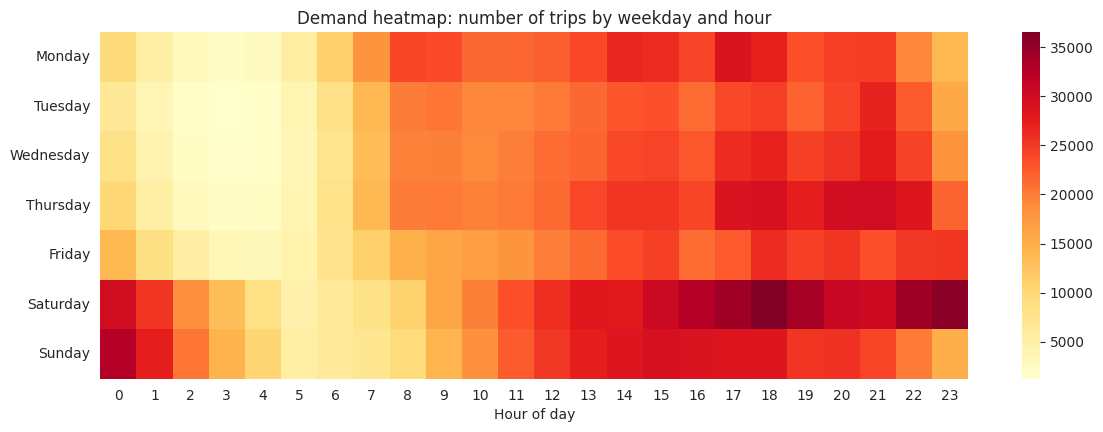

Top 5 busiest weekday-hour slots:
day_name  hour
Saturday  18      36532
          23      35648
          22      34265
          17      34159
          19      33730
dtype: int64


In [7]:
heat = df.pivot_table(index="day_name", columns="hour", values="total_amount", aggfunc="size").reindex(order)

plt.figure(figsize=(14, 4.5))
sns.heatmap(heat, cmap="YlOrRd")
plt.title("Demand heatmap: number of trips by weekday and hour")
plt.xlabel("Hour of day"); plt.ylabel("")
plt.show()

busiest = heat.stack().sort_values(ascending=False).head(5)
print("Top 5 busiest weekday-hour slots:")
print(busiest)

**Chart 4, top pickup zones**

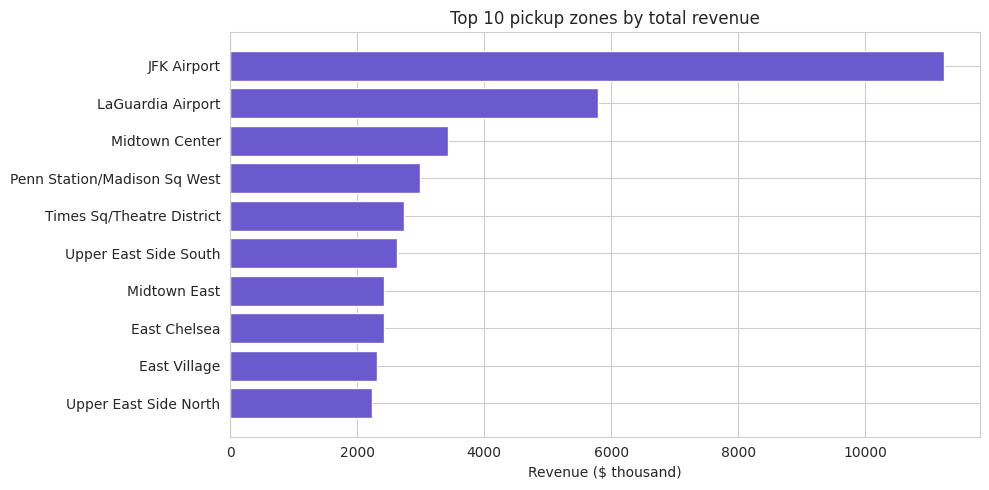

                     pu_zone pu_borough  trips     revenue  rev_per_trip  avg_dist
                 JFK Airport     Queens 145049 11246593.66         77.54     14.78
           LaGuardia Airport     Queens  84709  5796256.27         68.43      9.64
              Midtown Center  Manhattan 129874  3423164.25         26.36      2.41
Penn Station/Madison Sq West  Manhattan 111397  2983189.50         26.78      2.53
   Times Sq/Theatre District  Manhattan  92085  2727764.16         29.62      3.11
       Upper East Side South  Manhattan 121918  2630692.34         21.58      1.94
                Midtown East  Manhattan  95361  2415360.94         25.33      2.40
                East Chelsea  Manhattan  86483  2414286.02         27.92      2.87
                East Village  Manhattan  90248  2306518.32         25.56      2.98
       Upper East Side North  Manhattan  99435  2224320.74         22.37      2.27

Share of total revenue from top 10 zones:  40.5 %
Number of pickup zones in data: 258


In [8]:
zone_stats = df.groupby(["pu_zone", "pu_borough"]).agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"),
                                                        rev_per_trip=("total_amount", "mean"),
                                                        avg_dist=("trip_distance", "mean")).reset_index()

top_rev = zone_stats.sort_values("revenue", ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.barh(top_rev["pu_zone"][::-1], top_rev["revenue"][::-1] / 1000, color="slateblue")
plt.title("Top 10 pickup zones by total revenue")
plt.xlabel("Revenue ($ thousand)")
plt.tight_layout(); plt.show()

print(top_rev.round(2).to_string(index=False))
print("\nShare of total revenue from top 10 zones: ", round(top_rev["revenue"].sum() / total_revenue * 100, 1), "%")
print("Number of pickup zones in data:", len(zone_stats))

# zones with high earning per trip (at least 2000 trips so it is not a fluke)
rich = zone_stats[zone_stats["trips"] >= 2000].sort_values("rev_per_trip", ascending=False).head(8)
print("\nHighest revenue-per-trip zones (min 2000 trips):")
print(rich.round(2).to_string(index=False))

**Chart 5, borough splitd text**

                 trips      revenue  rev_per_trip  trip_share_%
pu_borough                                                     
Manhattan      2728204  70195878.54         25.73          87.0
Queens          295232  19912013.21         67.45           9.4
Brooklyn         94372   3442590.60         36.48           3.0
Bronx            13569    501388.71         36.95           0.4
Unknown           2392     85197.84         35.62           0.1
Staten Island      310     14080.01         45.42           0.0
EWR                 17      2118.35        124.61           0.0


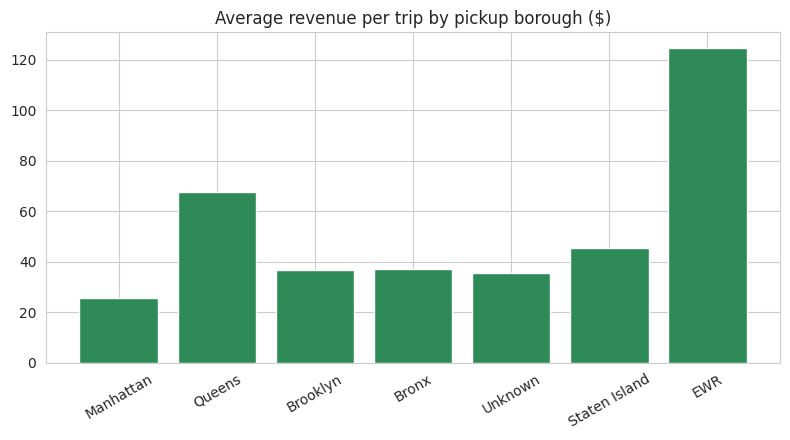

In [9]:
bor = df.groupby("pu_borough").agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"),
                                    rev_per_trip=("total_amount", "mean")).sort_values("revenue", ascending=False)
bor["trip_share_%"] = (bor["trips"] / bor["trips"].sum() * 100).round(1)
print(bor.round(2).to_string())

plt.figure(figsize=(8, 4.5))
plt.bar(bor.index, bor["rev_per_trip"], color="seagreen")
plt.title("Average revenue per trip by pickup borough ($)")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**Chart 6, trip distance vs earnings**

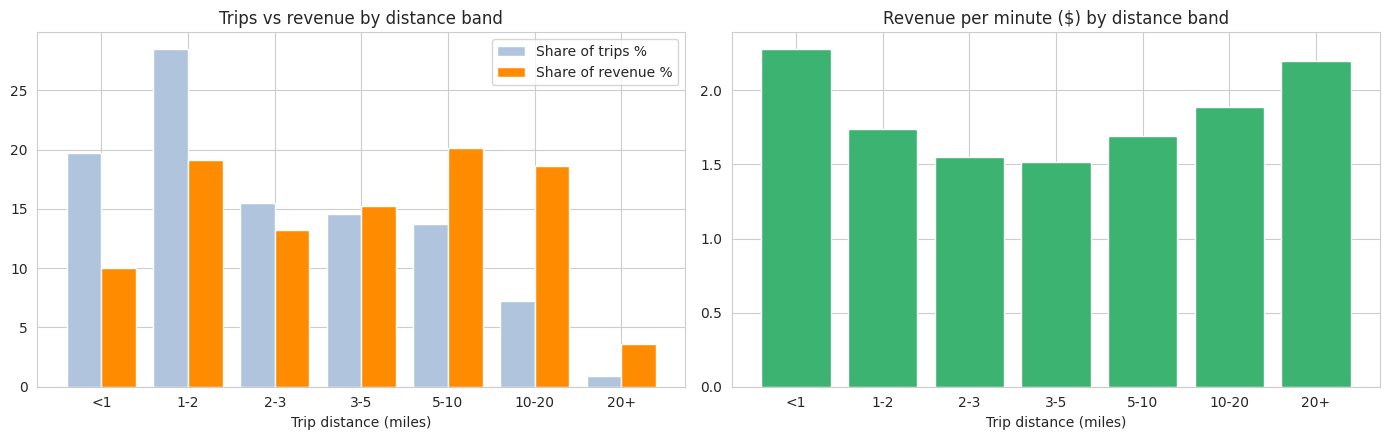

            trips      revenue        dist         mins  rev_per_trip  rev_per_mile  rev_per_min  trip_share_%  revenue_share_%
dist_band                                                                                                                      
<1         617351   9465132.58   432351.25   4155173.35         15.33         21.89         2.28         19.69            10.05
1-2        892133  17987650.75  1313594.91  10360992.53         20.16         13.69         1.74         28.46            19.09
2-3        484662  12469369.08  1192068.10   8033548.72         25.73         10.46         1.55         15.46            13.24
3-5        455260  14379302.23  1763108.08   9499663.57         31.58          8.16         1.51         14.52            15.26
5-10       429467  18953947.68  3053058.73  11189344.65         44.13          6.21         1.69         13.70            20.12
10-20      227702  17564555.78  3260517.85   9306101.17         77.14          5.39         1.89        

In [10]:
bins = [0, 1, 2, 3, 5, 10, 20, 100]
labels = ["<1", "1-2", "2-3", "3-5", "5-10", "10-20", "20+"]
df["dist_band"] = pd.cut(df["trip_distance"], bins=bins, labels=labels)

band = df.groupby("dist_band", observed=True).agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"),
                                                   dist=("trip_distance", "sum"), mins=("duration_min", "sum"),
                                                   rev_per_trip=("total_amount", "mean"))
band["rev_per_mile"] = band["revenue"] / band["dist"]
band["rev_per_min"] = band["revenue"] / band["mins"]
band["trip_share_%"] = band["trips"] / band["trips"].sum() * 100
band["revenue_share_%"] = band["revenue"] / band["revenue"].sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(band))
ax[0].bar(x - 0.2, band["trip_share_%"], 0.4, label="Share of trips %", color="lightsteelblue")
ax[0].bar(x + 0.2, band["revenue_share_%"], 0.4, label="Share of revenue %", color="darkorange")
ax[0].set_xticks(x); ax[0].set_xticklabels(band.index); ax[0].set_xlabel("Trip distance (miles)")
ax[0].set_title("Trips vs revenue by distance band"); ax[0].legend()

ax[1].bar(band.index.astype(str), band["rev_per_min"], color="mediumseagreen")
ax[1].set_title("Revenue per minute ($) by distance band"); ax[1].set_xlabel("Trip distance (miles)")
plt.tight_layout(); plt.show()
print(band.round(2).to_string())

**Chart 7, payment type and tips**

               trips  rev_per_trip  avg_tip  share_%
payment                                             
Credit card  1987971         29.89     4.28    63.42
Flex fare     822664         31.64     0.31    26.24
Cash          308215         26.95     0.00     9.83
Dispute        10167         30.87     0.00     0.32
No charge       5624         25.23     0.00     0.18


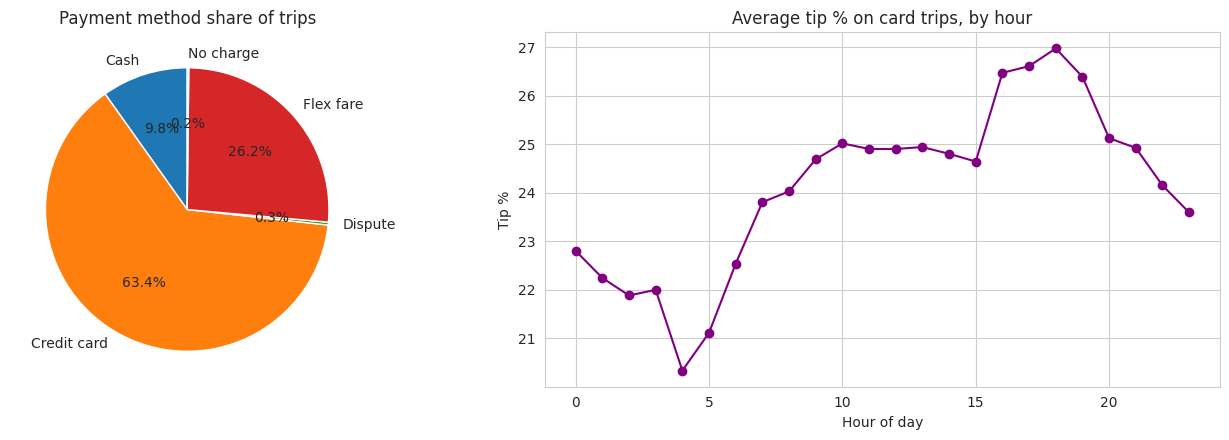

In [11]:
pay = df.groupby("payment").agg(trips=("total_amount", "size"), rev_per_trip=("total_amount", "mean"),
                                 avg_tip=("tip_amount", "mean"))
pay["share_%"] = pay["trips"] / pay["trips"].sum() * 100
print(pay.round(2).sort_values("trips", ascending=False).to_string())

card = df[df["payment_type"] == 1]
tip_hour = card.groupby("hour")["tip_pct"].mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].pie(pay["trips"], labels=pay.index, autopct="%1.1f%%", startangle=90)
ax[0].set_title("Payment method share of trips")
ax[1].plot(tip_hour.index, tip_hour.values, marker="o", color="purple")
ax[1].set_title("Average tip % on card trips, by hour"); ax[1].set_xlabel("Hour of day"); ax[1].set_ylabel("Tip %")
plt.tight_layout(); plt.show()

**Chart 8, airport trips**

               trips      revenue  rev_per_trip   dist   mins    tip  trip_share_%  revenue_share_%
Non-airport  2846893  72462030.16         25.45   2.81  15.31  25.40         90.82            76.91
Airport       287748  21748600.63         75.58  12.95  36.50  21.47          9.18            23.09


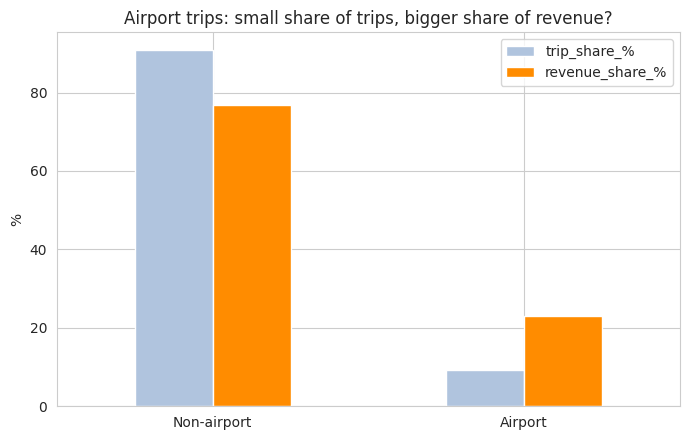

In [12]:
air = df.groupby("is_airport").agg(trips=("total_amount", "size"), revenue=("total_amount", "sum"),
                                    rev_per_trip=("total_amount", "mean"), dist=("trip_distance", "mean"),
                                    mins=("duration_min", "mean"), tip=("tip_pct", "mean"))
air.index = ["Non-airport", "Airport"]
air["trip_share_%"] = air["trips"] / air["trips"].sum() * 100
air["revenue_share_%"] = air["revenue"] / air["revenue"].sum() * 100
print(air.round(2).to_string())

air.loc[:, ["trip_share_%", "revenue_share_%"]].plot(kind="bar", figsize=(7, 4.5), color=["lightsteelblue", "darkorange"])
plt.title("Airport trips: small share of trips, bigger share of revenue?")
plt.ylabel("%"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**numbers for the report **

In [13]:
print("MONTH:", month_used)
print("Rows raw / clean:", rows_before, "/", len(df))
print("Peak trip hour:", hourly.loc[hourly["trips"].idxmax(), "hour"], "with", hourly["trips"].max(), "trips")
print("Quietest hour:", hourly.loc[hourly["trips"].idxmin(), "hour"], "with", hourly["trips"].min(), "trips")
print("Best revenue/trip hour:", hourly.loc[hourly["rev_per_trip"].idxmax(), "hour"], round(hourly["rev_per_trip"].max(), 2))
print("Best revenue/min hour:", hourly.loc[hourly["rev_per_min"].idxmax(), "hour"], round(hourly["rev_per_min"].max(), 2))
print("Weekend vs weekday revenue per trip:", df.groupby("is_weekend")["total_amount"].mean().round(2).to_dict())
print("Median fare:", df["fare_amount"].median(), "| median distance:", df["trip_distance"].median())
print("Avg speed (mph):", round(df["speed_mph"].mean(), 1))
print("Avg passengers:", round(df["passenger_count"].mean(), 2))
print("Top pickup zone:", zone_stats.sort_values("trips", ascending=False).iloc[0][["pu_zone", "trips"]].to_dict())

MONTH: 2026-08
Rows raw / clean: 3336716 / 3134641
Peak trip hour: 18 with 199032 trips
Quietest hour: 4 with 29798 trips
Best revenue/trip hour: 5 33.42
Best revenue/min hour: 5 2.05
Weekend vs weekday revenue per trip: {False: 30.12, True: 29.93}
Median fare: 15.6 | median distance: 2.1
Avg speed (mph): 11.6
Avg passengers: 1.27
Top pickup zone: {'pu_zone': 'JFK Airport', 'trips': 145049}
